In [2]:
import pandas as pd
import numpy as np
import os

# Load the data
imdb_movies_df = pd.read_csv("dataset/IMDB_movies.csv", sep=",")
train_df = pd.read_csv('dataset/Multi_Label_dataset/train.csv')

In [ ]:
# Check for null values
print(imdb_movies_df.isnull().sum())
print(train_df.isnull().sum())

In [4]:
#A lot of columns have missing values, we will adapt our code accordingly

In [5]:
# Split the Genre column into a list of genres
imdb_movies_df['genre'] = imdb_movies_df['genre'].str.split(',')

# Encode genres into separate columns
imdb_movies_df = imdb_movies_df.join(imdb_movies_df.pop('genre').str.get_dummies(','))

In [6]:
from keras.applications.vgg16 import VGG16
from keras.preprocessing import image
from keras.applications.vgg16 import preprocess_input
import numpy as np
import tensorflow as tf
from tensorflow.keras.utils import load_img, img_to_array


2023-06-01 12:06:37.543097: I tensorflow/core/platform/cpu_feature_guard.cc:182] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [7]:
model = VGG16(weights='imagenet', include_top=False)

In [8]:
def extract_features(img_path, model):
    try:
        img = load_img(img_path, target_size=(224, 224))
        img_data = img_to_array(img)
        img_data = np.expand_dims(img_data, axis=0)
        img_data = preprocess_input(img_data)
    
        vgg16_features = model.predict(img_data)
        return vgg16_features
    except Exception as e:
        print(f"Error: {e} for image path {img_path}")
        return None


In [ ]:
poster_features = {}
for movie_id in train_df['Id']:
    img_path = 'dataset/Multi_Label_dataset/Images/' + movie_id + '.jpg'
    features = extract_features(img_path, model)
    if features is not None:
        poster_features[movie_id] = features


In [10]:
train_df['Poster_Features'] = train_df['Id'].map(poster_features)

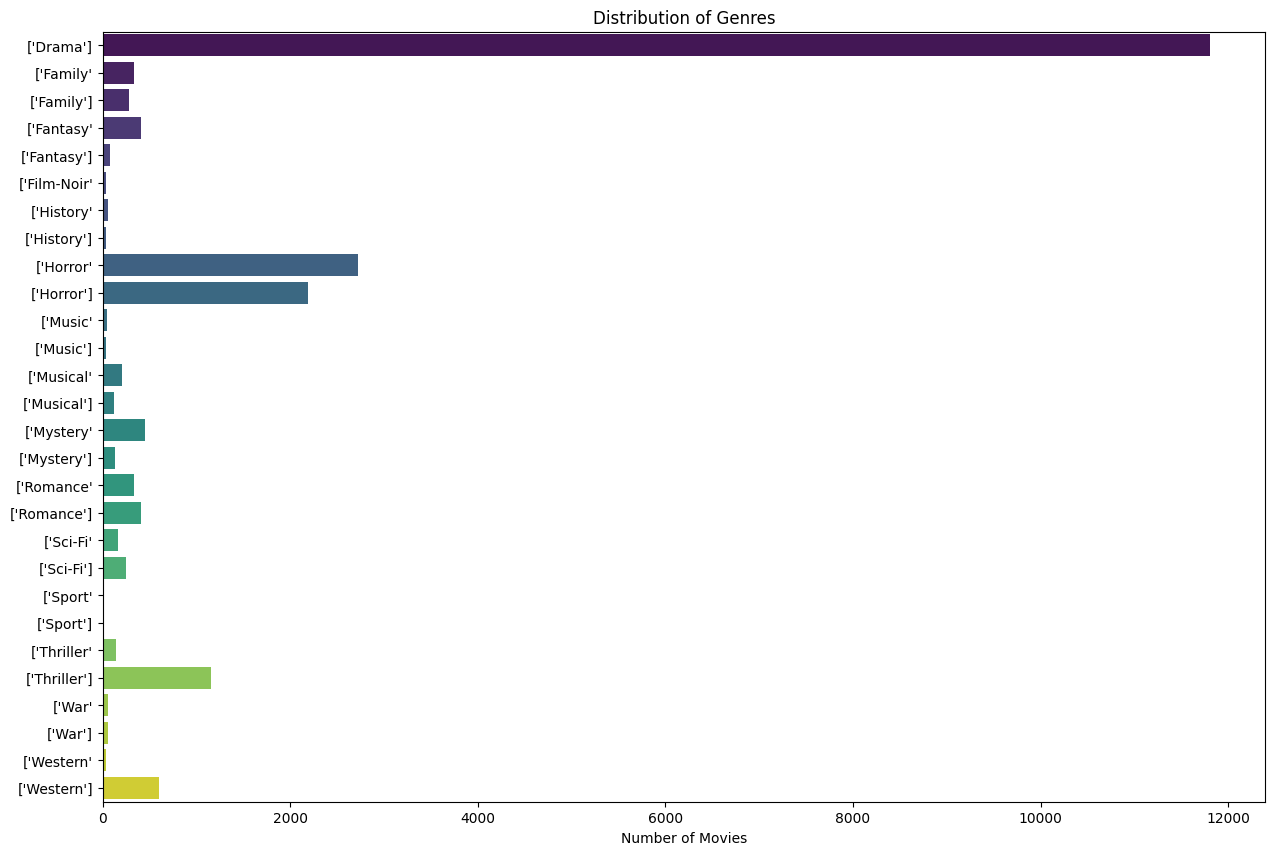

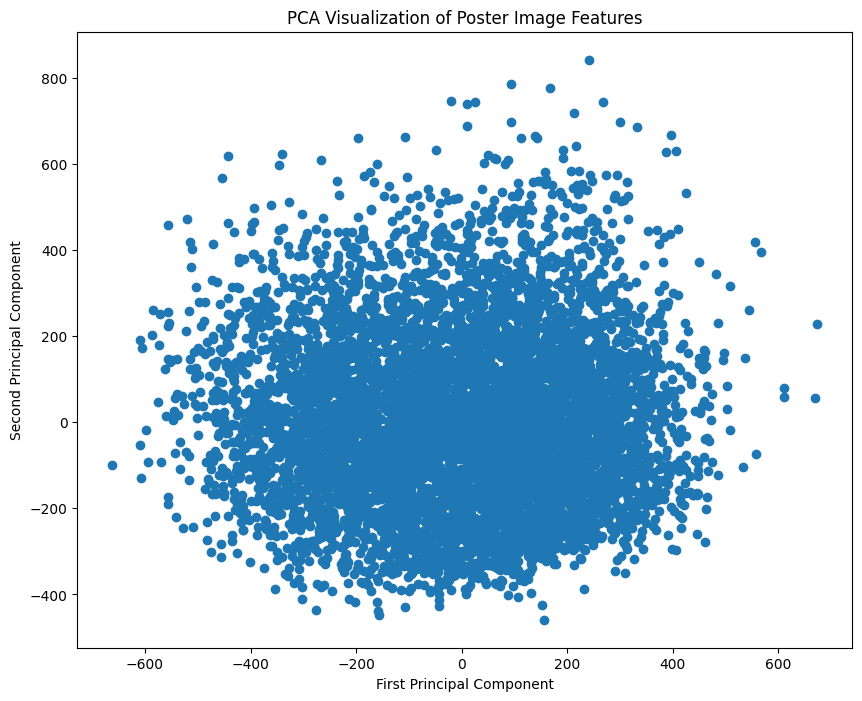

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA

# Calculate the total count of each genre
genre_counts = imdb_movies_df.iloc[:, -28:].sum(axis=0)

# Create a bar plot for genres
plt.figure(figsize=(15,10))
sns.barplot(x=genre_counts.values, y=genre_counts.index, palette='viridis')
plt.title('Distribution of Genres')
plt.xlabel('Number of Movies')
plt.show()

# Extract features from the Poster_Features column and convert them into a 2D numpy array
poster_features = np.array(train_df['Poster_Features'].apply(lambda x: np.array(x).flatten()).tolist())

# Apply PCA to the poster features
pca = PCA(n_components=2)
reduced_features = pca.fit_transform(poster_features)

# Create a scatter plot
plt.figure(figsize=(10,8))
plt.scatter(reduced_features[:, 0], reduced_features[:, 1])
plt.xlabel('First Principal Component')
plt.ylabel('Second Principal Component')
plt.title('PCA Visualization of Poster Image Features')
plt.show()


In [14]:
from sklearn.preprocessing import MultiLabelBinarizer
from sklearn.preprocessing import StandardScaler

# Transforming the genre labels into binary vectors
mlb = MultiLabelBinarizer()
train_df['Genre'] = train_df['Genre'].str.split(',')
train_df = train_df.join(pd.DataFrame(mlb.fit_transform(train_df.pop('Genre')),
                          columns=mlb.classes_,
                          index=train_df.index))

# Flattening and Scaling the extracted features
features = np.array(train_df['Poster_Features'].tolist())
features = features.reshape(features.shape[0], -1)
scaler = StandardScaler()
features_scaled = scaler.fit_transform(features)

# Replace Poster_Features with the scaled features
train_df['Poster_Features'] = list(features_scaled)

In [15]:
from sklearn.model_selection import train_test_split
from keras.models import Sequential
from keras.layers import Dense

# Preparing the labels and features for training
labels = train_df.drop(['Id', 'Poster_Features'], axis=1).values
features = np.stack(train_df['Poster_Features'].values)

# Splitting the dataset into training and testing sets
features_train, features_test, labels_train, labels_test = train_test_split(features, labels, test_size=0.2, random_state=42)

# Building the model
model = Sequential()
model.add(Dense(512, input_shape=(features.shape[1],), activation='relu'))
model.add(Dense(256, activation='relu'))
model.add(Dense(labels.shape[1], activation='sigmoid'))

# Compiling the model
model.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])

In [16]:
# Training the model
model.fit(features_train, labels_train, epochs=10, batch_size=64, validation_data=(features_test, labels_test))

# Evaluating the model
scores = model.evaluate(features_test, labels_test)
print(f"Model accuracy: {scores[1]*100}%")

Epoch 1/10
91/91 [==============================] - 15s 137ms/step - loss: 0.1747 - accuracy: 0.2638 - val_loss: 0.1316 - val_accuracy: 0.2853
Epoch 2/10
91/91 [==============================] - 12s 134ms/step - loss: 0.0550 - accuracy: 0.3881 - val_loss: 0.1506 - val_accuracy: 0.3184
Epoch 3/10
91/91 [==============================] - 12s 128ms/step - loss: 0.0145 - accuracy: 0.3870 - val_loss: 0.1796 - val_accuracy: 0.3239
Epoch 4/10
91/91 [==============================] - 12s 131ms/step - loss: 0.0043 - accuracy: 0.3862 - val_loss: 0.2016 - val_accuracy: 0.3418
Epoch 5/10
91/91 [==============================] - 12s 128ms/step - loss: 0.0018 - accuracy: 0.4084 - val_loss: 0.2208 - val_accuracy: 0.3494
Epoch 6/10
91/91 [==============================] - 11s 127ms/step - loss: 9.3946e-04 - accuracy: 0.4262 - val_loss: 0.2367 - val_accuracy: 0.3577
Epoch 7/10
91/91 [==============================] - 12s 129ms/step - loss: 5.1900e-04 - accuracy: 0.4513 - val_loss: 0.2476 - val_accuracy

In [19]:
from colorthief import ColorThief
import os

# Function to get the dominant color of an image
def get_dominant_color(movie_id):
    img_path = 'dataset/Multi_Label_dataset/Images/' + movie_id + '.jpg'
    if os.path.exists(img_path):
        color_thief = ColorThief(img_path)
        dominant_color = color_thief.get_color(quality=1)
        return dominant_color
    else:
        return None

# Apply the function to each movie in the dataset
train_df['Dominant_Color'] = train_df['Id'].apply(get_dominant_color)
